 Import Required Libraries


In [15]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import sklearn
from scipy.stats import skew
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
try:
    from xgboost import XGBRegressor
    print("XGBoost available")
except ImportError:
    XGBRegressor = None
    print("XGBoost missing -> run: !pip install xgboost  (then restart kernel)")

TARGET, SEED = "median_house_value", 42
print("Imports OK | scikit-learn", sklearn.__version__)

XGBoost available
Imports OK | scikit-learn 1.6.1


**Load data**

In [16]:
df = pd.read_csv("housing.csv")
print("Shape:", df.shape)
df.head()

Shape: (20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


**Data overview (types, missing values, statistics)**

In [17]:
print("Duplicates:", df.duplicated().sum())
print("\nMissing values:")
print(df.isna().sum()[df.isna().sum() > 0])
df.describe().T.round(2)

Duplicates: 0

Missing values:
total_bedrooms    207
dtype: int64


,count,mean,std,min,25%,50%,75%,max
longitude,20640.0,-119.57,2.00,-124.35,-121.80,-118.49,-118.01,-114.31
latitude,20640.0,35.63,2.14,32.54,33.93,34.26,37.71,41.95
housing_median_age,20640.0,28.64,12.59,1.00,18.00,29.00,37.00,52.00
total_rooms,20640.0,2635.76,2181.62,2.00,1447.75,2127.00,3148.00,39320.00
total_bedrooms,20433.0,537.87,421.39,1.00,296.00,435.00,647.00,6445.00
population,20640.0,1425.48,1132.46,3.00,787.00,1166.00,1725.00,35682.00
households,20640.0,499.54,382.33,1.00,280.00,409.00,605.00,6082.00
median_income,20640.0,3.87,1.90,0.50,2.56,3.53,4.74,15.00
median_house_value,20640.0,206855.82,115395.62,14999.00,119600.00,179700.00,264725.00,500001.00


**Skewness and log transform of the target**

Skew of raw price   : 0.978
Skew of log1p(price): -0.173


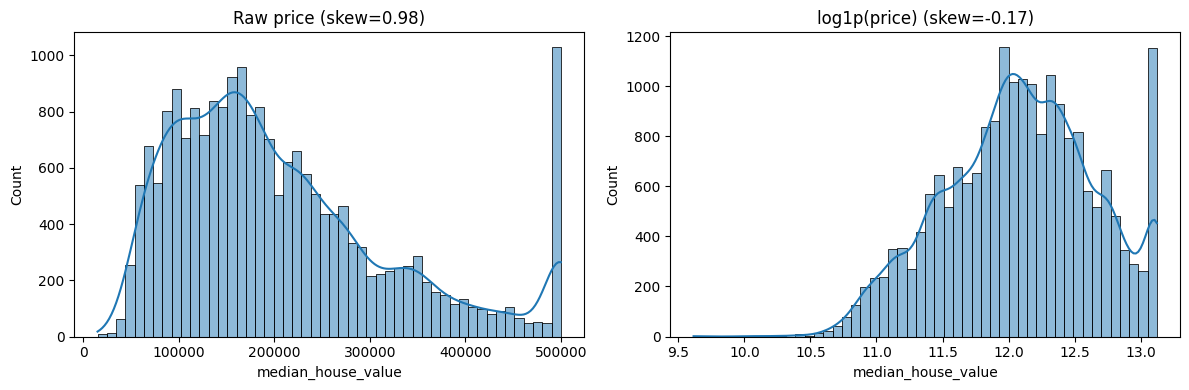

In [18]:
sk_raw = skew(df[TARGET])
sk_log = skew(np.log1p(df[TARGET]))
print(f"Skew of raw price   : {sk_raw:.3f}")
print(f"Skew of log1p(price): {sk_log:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df[TARGET], bins=50, kde=True, ax=ax[0]); ax[0].set_title(f"Raw price (skew={sk_raw:.2f})")
sns.histplot(np.log1p(df[TARGET]), bins=50, kde=True, ax=ax[1]); ax[1].set_title(f"log1p(price) (skew={sk_log:.2f})")
plt.tight_layout()
plt.show()

**Outlier detection (visual and counts**

Rows that will be capped by the pipeline:


,feature,extreme_outliers (3xIQR)
0,longitude,0
1,latitude,0
2,housing_median_age,0
3,total_rooms,494
4,total_bedrooms,443
5,population,421
6,households,415
7,median_income,140


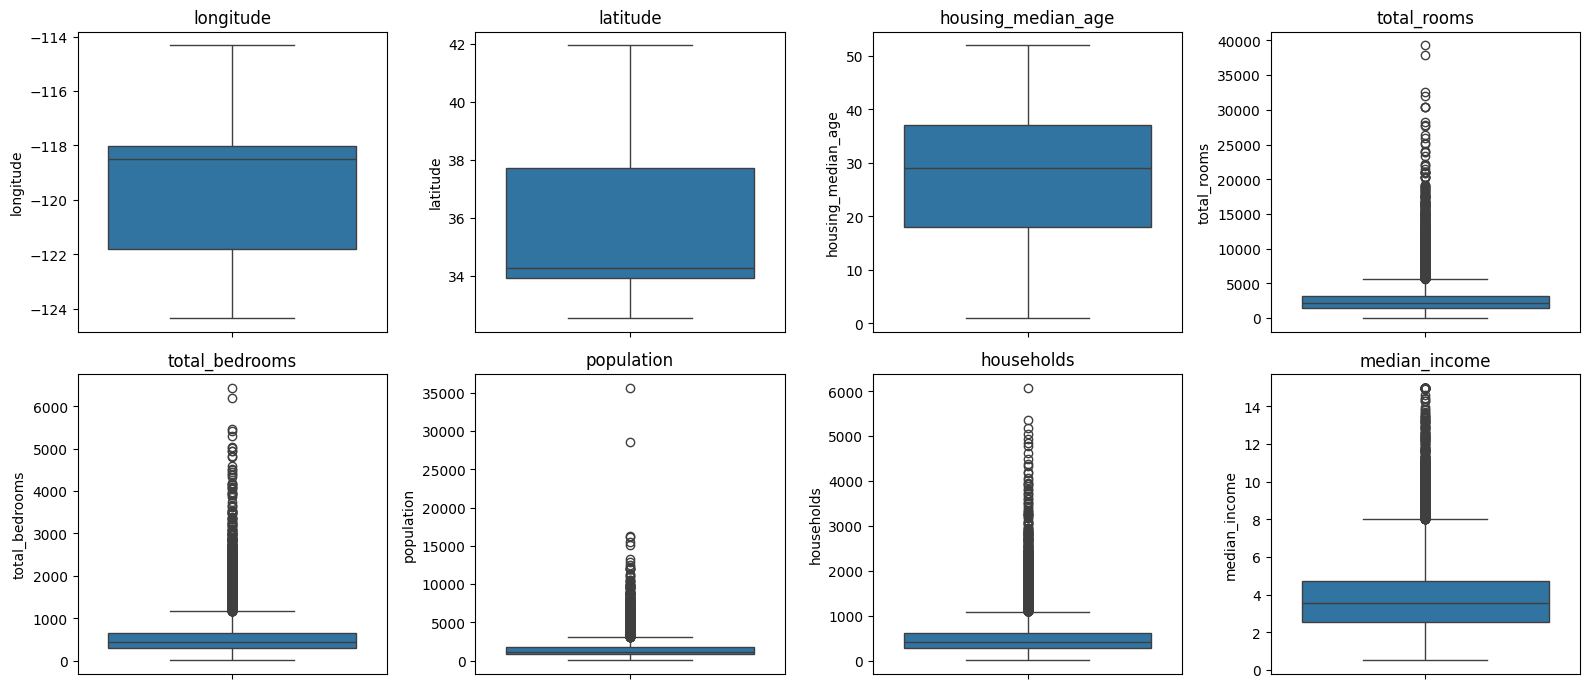

In [20]:
num_all = df.select_dtypes("number").columns
feat_cols = [c for c in num_all if c != TARGET]

rows = []
for c in feat_cols:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = ((df[c] < q1 - 3 * iqr) | (df[c] > q3 + 3 * iqr)).sum()
    rows.append({"feature": c, "extreme_outliers (3xIQR)": n_out})
print("Rows that will be capped by the pipeline:")
display(pd.DataFrame(rows))

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, c in zip(axes.ravel(), feat_cols):
    sns.boxplot(y=df[c], ax=ax)
    ax.set_title(c)
plt.tight_layout()
plt.show()

**Remove target outliers before and after**

In [21]:
n0 = len(df)
df = df.drop_duplicates()
print("After dropping duplicates:", len(df))

cap_value = df[TARGET].max()
n_capped = (df[TARGET] == cap_value).sum()
df = df[df[TARGET] < cap_value]
print(f"Dropped {n_capped} rows with capped (censored) price = {cap_value:,.0f}")

lo, hi = np.log1p(df[TARGET]).quantile([0.01, 0.99])
df = df[np.log1p(df[TARGET]).between(lo, hi)].reset_index(drop=True)
print(f"After trimming 1% / 99% log-price tails: {len(df)} rows (removed {n0 - len(df)} in total)")
print("Price range now:", f"{df[TARGET].min():,.0f} to {df[TARGET].max():,.0f}")

After dropping duplicates: 20640
Dropped 965 rows with capped (censored) price = 500,001
After trimming 1% / 99% log-price tails: 19284 rows (removed 1356 in total)
Price range now: 49,800 to 464,300


**Feature engineering**

In [22]:
df["rooms_per_household"] = df["total_rooms"] / df["households"]
df["bedrooms_per_room"] = df["total_bedrooms"] / df["total_rooms"]
df["population_per_household"] = df["population"] / df["households"]
df[["total_rooms", "households", "rooms_per_household",
    "bedrooms_per_room", "population_per_household"]].head()

,total_rooms,households,rooms_per_household,bedrooms_per_room,population_per_household
0,880.0,126.0,6.984127,0.146591,2.555556
1,7099.0,1138.0,6.238137,0.155797,2.109842
2,1467.0,177.0,8.288136,0.129516,2.802260
3,1274.0,219.0,5.817352,0.184458,2.547945
4,1627.0,259.0,6.281853,0.172096,2.181467


**Train/test split**

In [23]:
X, y = df.drop(columns=TARGET), df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)

cat_cols = ["ocean_proximity"]
num_cols = [c for c in X.columns if c not in cat_cols]

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("Numeric features:", num_cols)
print("Categorical features:", cat_cols)
print("\nocean_proximity in train:")
print(X_train["ocean_proximity"].value_counts())

X_train: (15427, 12) | X_test: (3857, 12)
Numeric features: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household']
Categorical features: ['ocean_proximity']

ocean_proximity in train:
ocean_proximity
<1H OCEAN     6782
INLAND        5061
NEAR OCEAN    1909
NEAR BAY      1672
ISLAND           3
Name: count, dtype: int64


**Preprocessing pipeline imputer, outlier capper, one-hot**

In [24]:
class IQRCapper(BaseEstimator, TransformerMixin):
    """Cap values at Q1 - k*IQR and Q3 + k*IQR. Bounds are learned on train data only."""
    def __init__(self, k=3.0):
        self.k = k
    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        q1, q3 = np.nanpercentile(X, 25, axis=0), np.nanpercentile(X, 75, axis=0)
        self.lo_, self.hi_ = q1 - self.k * (q3 - q1), q3 + self.k * (q3 - q1)
        return self
    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.lo_, self.hi_)
    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)

prep = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("cap", IQRCapper())]), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
])

Xt = prep.fit_transform(X_train)
print("Transformed train shape:", Xt.shape)
print("NaNs after preprocessing:", int(np.isnan(Xt).sum()))
pd.DataFrame(Xt, columns=prep.get_feature_names_out()).head()

Transformed train shape: (15427, 16)
NaNs after preprocessing: 0


,num__longitude,num__latitude,num__housing_median_age,num__total_rooms,num__total_bedrooms,num__population,num__households,num__median_income,num__rooms_per_household,num__bedrooms_per_room,num__population_per_household,cat__ocean_proximity_<1H OCEAN,cat__ocean_proximity_INLAND,cat__ocean_proximity_ISLAND,cat__ocean_proximity_NEAR BAY,cat__ocean_proximity_NEAR OCEAN
0,-117.63,34.06,39.0,1210.0,310.0,1294.0,303.0,2.3636,3.993399,0.256198,4.270627,0.0,1.0,0.0,0.0,0.0
1,-118.14,34.10,52.0,4061.0,861.0,2290.0,790.0,2.8919,5.140506,0.212017,2.898734,1.0,0.0,0.0,0.0,0.0
2,-119.74,36.15,21.0,1548.0,308.0,1137.0,306.0,2.4688,5.058824,0.198966,3.715686,0.0,1.0,0.0,0.0,0.0
3,-121.45,38.54,41.0,1278.0,308.0,839.0,280.0,1.4702,4.564286,0.241002,2.996429,0.0,1.0,0.0,0.0,0.0
4,-118.15,33.86,34.0,2403.0,413.0,1385.0,386.0,4.4934,6.225389,0.171868,3.588083,1.0,0.0,0.0,0.0,0.0


**Define the models log1p on the target**

In [25]:
def make_model(reg):
    pipe = Pipeline([("prep", prep), ("model", reg)])
    return TransformedTargetRegressor(regressor=pipe, func=np.log1p, inverse_func=np.expm1)

models = {"GBR": make_model(GradientBoostingRegressor(
    n_estimators=400, learning_rate=0.05, max_depth=4, subsample=0.8, random_state=SEED))}
if XGBRegressor is not None:
    models["XGBoost"] = make_model(XGBRegressor(
        n_estimators=600, learning_rate=0.05, max_depth=6, subsample=0.8,
        colsample_bytree=0.8, n_jobs=-1, random_state=SEED))

print("Models defined:", list(models.keys()))

Models defined: ['GBR', 'XGBoost']


**5-fold cross-validation takes a minute or two**

In [26]:
cv_rows = []
for name, m in models.items():
    scores = -cross_val_score(m, X_train, y_train, cv=5, scoring="neg_root_mean_squared_error")
    cv_rows.append({"Model": name, "CV RMSE (mean)": scores.mean(), "CV RMSE (std)": scores.std()})
    print(f"{name}: fold RMSEs = {np.round(scores, 0)}")
cv_df = pd.DataFrame(cv_rows).round(1)
cv_df

GBR: fold RMSEs = [41897. 43181. 43042. 42286. 43531.]
XGBoost: fold RMSEs = [38217. 40643. 40404. 39631. 40965.]


,Model,CV RMSE (mean),CV RMSE (std)
0,GBR,42787.4,602.9
1,XGBoost,39971.9,981.8


**Fit and evaluate on the test set**

In [27]:
results, preds = [], {}
for name, m in models.items():
    m.fit(X_train, y_train)
    preds[name] = m.predict(X_test)
    results.append({
        "Model": name,
        "RMSE": np.sqrt(mean_squared_error(y_test, preds[name])),
        "MAE": mean_absolute_error(y_test, preds[name]),
        "R2": r2_score(y_test, preds[name]),
        "MAPE %": np.mean(np.abs((y_test - preds[name]) / y_test)) * 100,
    })
results_df = pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True)
best_name = results_df.loc[0, "Model"]
print("Best model on test set:", best_name)
results_df.round(3)

Best model on test set: XGBoost


,Model,RMSE,MAE,R2,MAPE %
0,XGBoost,39242.748,25846.952,0.818,14.459
1,GBR,42113.318,28422.991,0.790,15.941


**Actual vs predicted and residuals for each model**

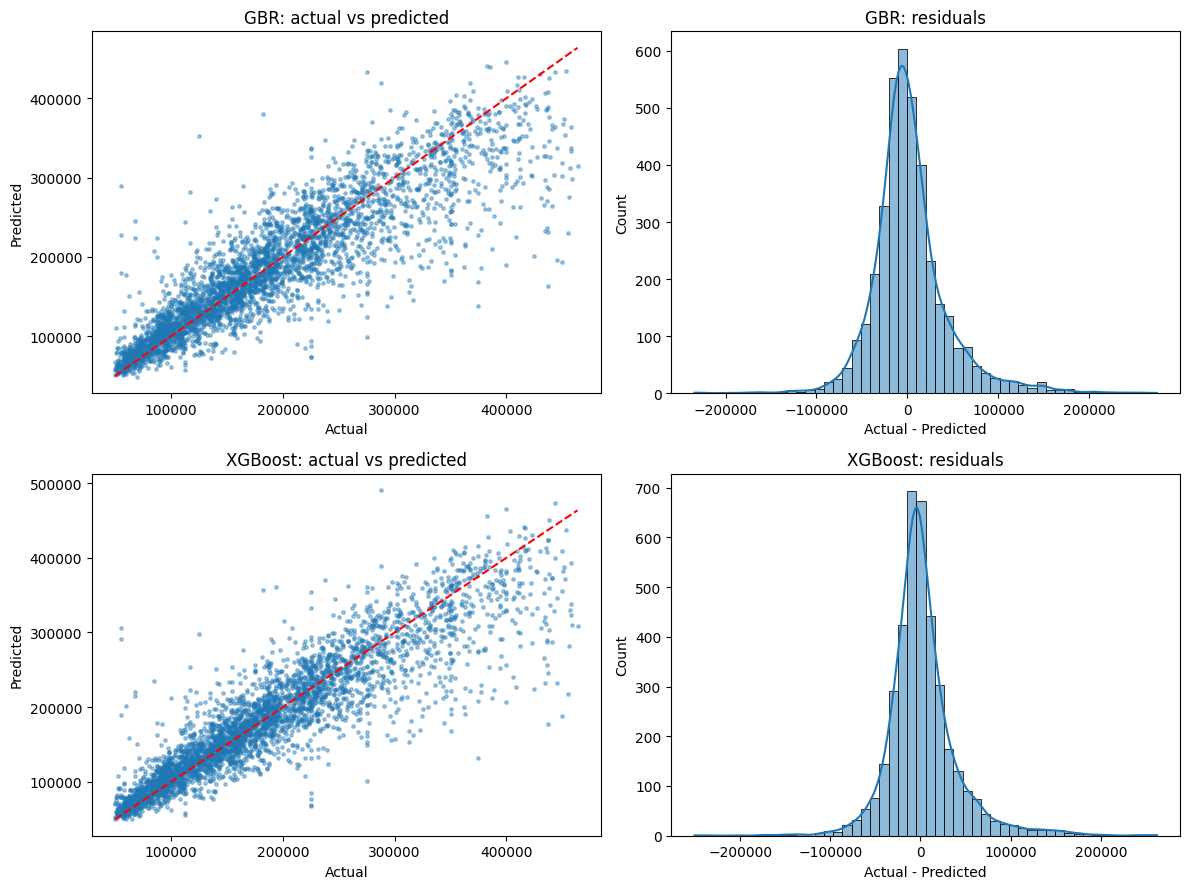

In [28]:
fig, axes = plt.subplots(len(preds), 2, figsize=(12, 4.5 * len(preds)), squeeze=False)
for i, (name, p) in enumerate(preds.items()):
    axes[i, 0].scatter(y_test, p, s=6, alpha=0.4)
    axes[i, 0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
    axes[i, 0].set(title=f"{name}: actual vs predicted", xlabel="Actual", ylabel="Predicted")
    sns.histplot(y_test - p, bins=50, kde=True, ax=axes[i, 1])
    axes[i, 1].set(title=f"{name}: residuals", xlabel="Actual - Predicted")
plt.tight_layout()
plt.show()

**Feature importance of the best model**

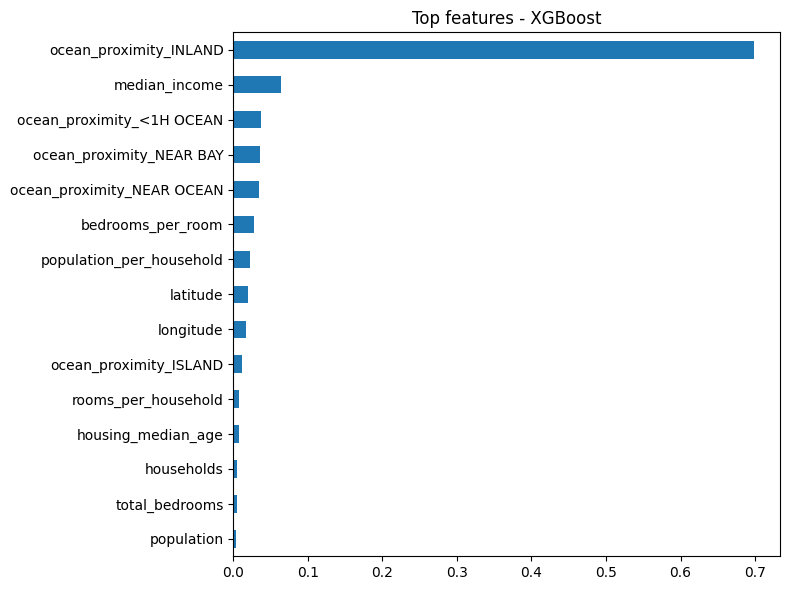

,importance
ocean_proximity_INLAND,0.6986
median_income,0.0644
ocean_proximity_<1H OCEAN,0.0367
ocean_proximity_NEAR BAY,0.0355
ocean_proximity_NEAR OCEAN,0.0346
bedrooms_per_room,0.0271
population_per_household,0.0229
latitude,0.0199
longitude,0.0169
ocean_proximity_ISLAND,0.0109


In [29]:
best = models[best_name].regressor_
names = [n.split("__")[-1] for n in best.named_steps["prep"].get_feature_names_out()]
imp = pd.Series(best.named_steps["model"].feature_importances_, index=names).sort_values()

imp.tail(15).plot.barh(figsize=(8, 6), title=f"Top features - {best_name}")
plt.tight_layout()
plt.show()
imp.sort_values(ascending=False).head(10).round(4).to_frame("importance")

**Predict on new raw rows and save the model**

In [30]:
import joblib
joblib.dump(models[best_name], "best_housing_model.joblib")

sample = X_test.head(5)
out = pd.DataFrame({
    "predicted": models[best_name].predict(sample).round(0),
    "actual": y_test.head(5).values,
})
out["error"] = (out["predicted"] - out["actual"]).round(0)
print("Model saved to best_housing_model.joblib")
out

Model saved to best_housing_model.joblib


,predicted,actual,error
0,339015.0,332500.0,6515.0
1,148735.0,163900.0,-15165.0
2,336466.0,277700.0,58766.0
3,85403.0,225000.0,-139597.0
4,213878.0,236600.0,-22722.0
